# National Education Performance & Retention Analytics
Longitudinal cohort tracking, regional directorate (AREF) disparity ranking, and multivariate dropout driver analysis (2020–2026).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
summary = json.loads((root / 'data/processed/executive_summary.json').read_text(encoding='utf-8'))
pd.Series(summary)

cohorts_analyzed                                 2020-2021 to 2025-2026
regional_directorates_count                                          12
total_cohort_records                                                432
latest_year_enrolled                                            8969238
latest_year_dropouts                                             367251
baseline_2020_dropout_rate_pct                                     4.73
latest_2025_dropout_rate_pct                                       4.09
six_year_dropout_reduction_bps                                     64.0
highest_disparity_aref                                   Draa-Tafilalet
highest_disparity_dropout_pct                                      6.83
lowest_disparity_aref                              Dakhla-Oued Ed-Dahab
lowest_disparity_dropout_pct                                       2.12
driver_model_r2                                                  0.7875
top_dropout_driver                Lower Secondary Transition Bot

In [2]:
regional = pd.read_csv(root / 'data/processed/regional_disparity_kpis.csv')
latest = regional[regional['academic_year'] == '2025-2026'].sort_values('disparity_priority_rank')
display(latest[['disparity_priority_rank', 'aref_code', 'aref_name', 'macro_zone', 'total_enrolled', 'total_dropouts', 'weighted_dropout_pct', 'yoy_dropout_delta_pct']])

,disparity_priority_rank,aref_code,aref_name,macro_zone,total_enrolled,total_dropouts,weighted_dropout_pct,yoy_dropout_delta_pct
0,1,AREF-08,Draa-Tafilalet,Southeast,322441,22030,6.83,0.15
1,2,AREF-07,Marrakech-Safi,Central-South,1175432,69397,5.90,-0.03
2,3,AREF-05,Beni Mellal-Khenifra,Central,833559,46704,5.60,-0.03
3,4,AREF-01,Tanger-Tetouan-Al Hoceima,North,496547,24843,5.00,0.07
4,5,AREF-03,Fes-Meknes,Central-North,1321297,57487,4.35,-0.20
5,6,AREF-02,Oriental,Northeast,283696,12251,4.32,-0.24
6,7,AREF-09,Souss-Massa,South-Central,888211,38214,4.30,-0.19
7,8,AREF-10,Guelmim-Oued Noun,South,653499,24565,3.76,-0.18
8,9,AREF-04,Rabat-Sale-Kenitra,Northwest,897599,24949,2.78,-0.39
9,10,AREF-06,Casablanca-Settat,Coastal-Central,599068,14574,2.43,-0.03


,feature_code,driver_name,standardized_beta,abs_impact,direction
0,is_lower_secondary,Lower Secondary Transition Bottleneck,2.1068,2.1068,Increases Dropout
1,is_rural,Rural School Location Exposure,1.7222,1.7222,Increases Dropout
2,grade_repetition_pct,Grade Repetition Rate (%),0.7820,0.7820,Increases Dropout
3,boarding_transport_coverage_pct,Boarding & Transport Support Coverage (%),-0.6309,0.6309,Reduces Dropout
4,exam_pass_rate_pct,Regional Exam Pass Rate (%),-0.4068,0.4068,Reduces Dropout
5,avg_commute_km,Average Student Commute Distance (km),0.2137,0.2137,Increases Dropout


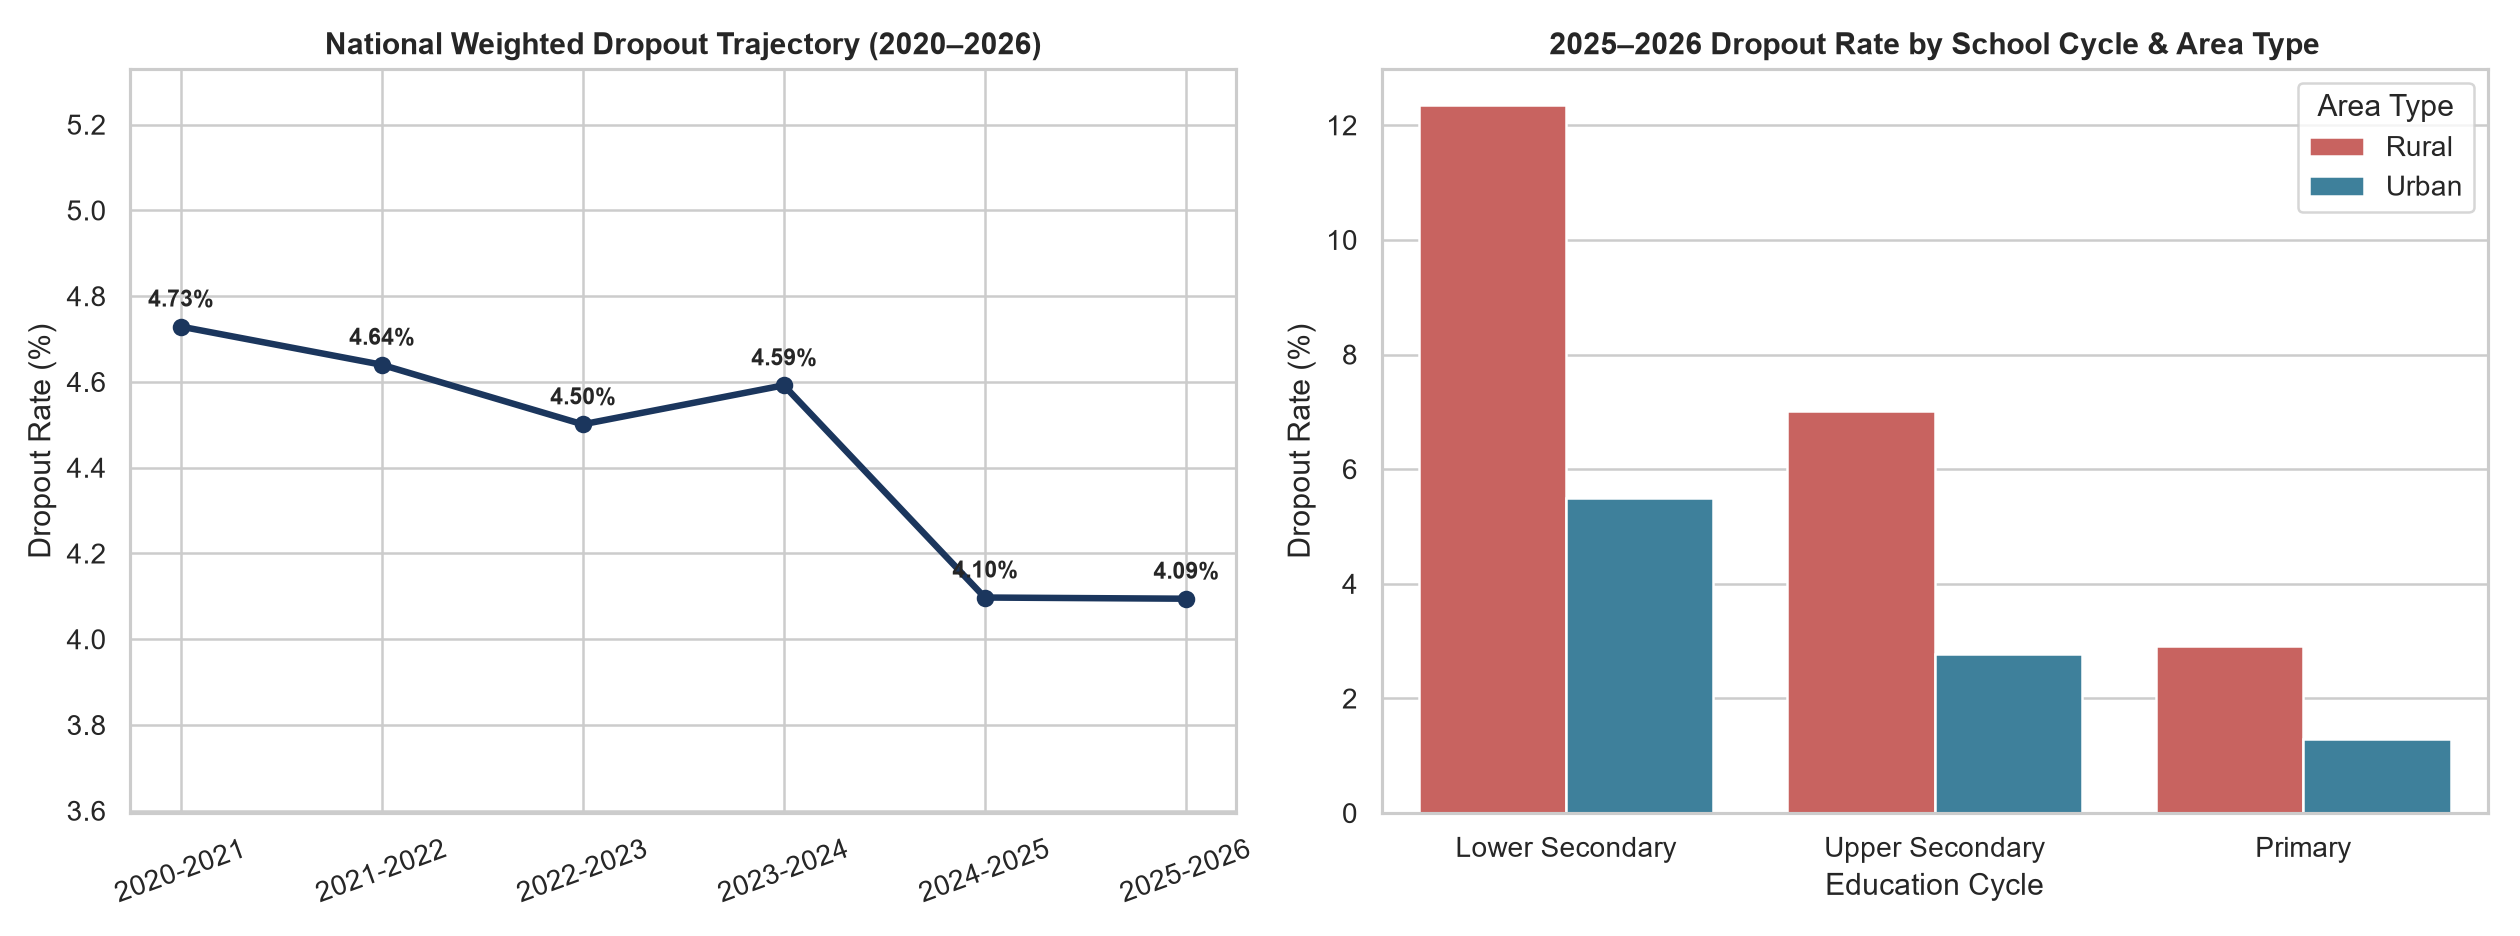

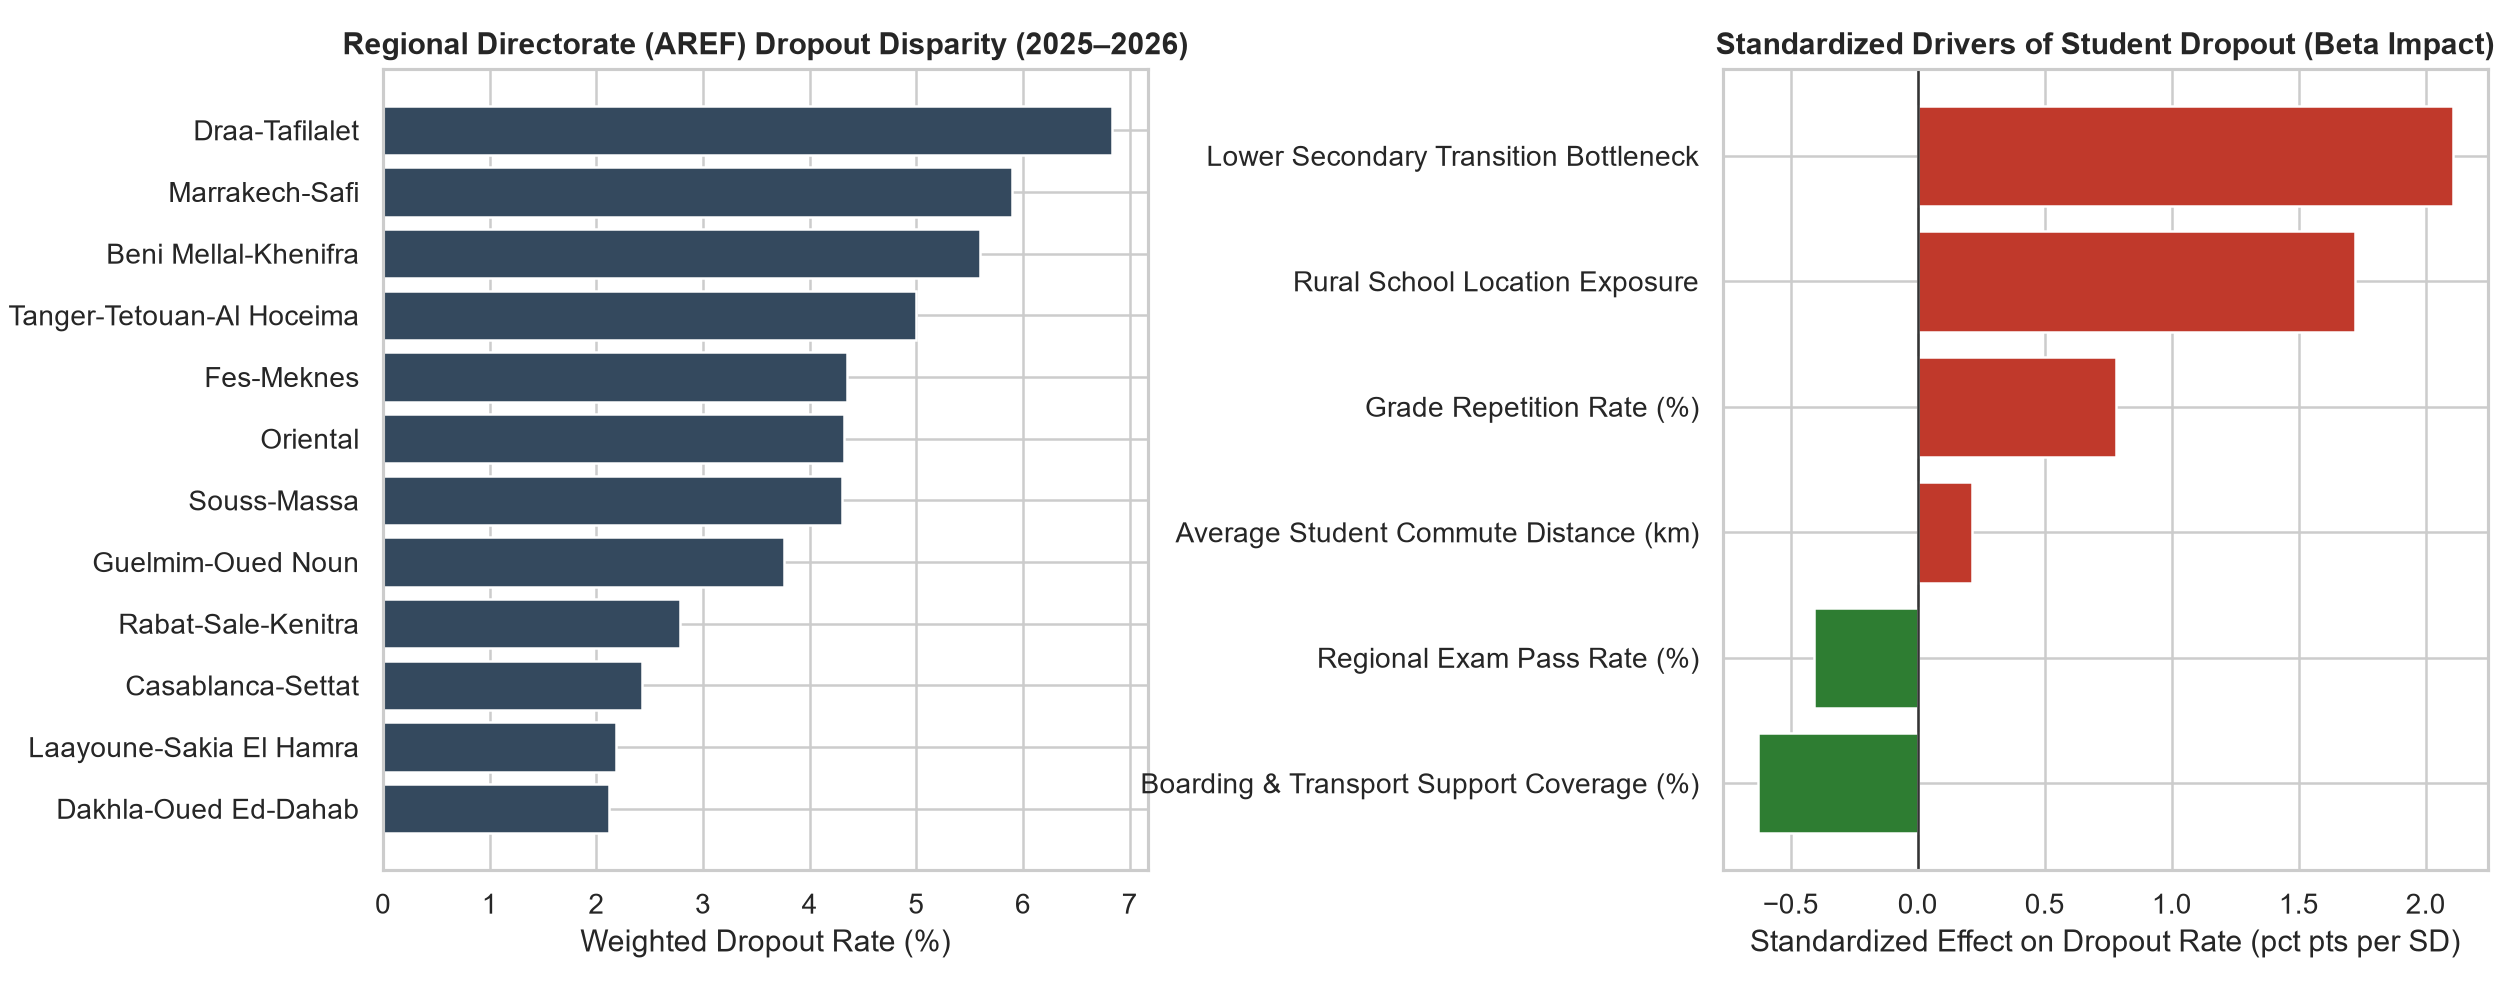

In [3]:
drivers = pd.read_csv(root / 'data/processed/dropout_drivers_ranked.csv')
display(drivers)
display(Image(filename=str(root / 'assets/executive_kpi_dashboard.png')))
display(Image(filename=str(root / 'assets/dropout_drivers_disparity.png')))